# Module 10 — Estimation and Sampling

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first,
or keep it open alongside. Every section below mirrors a numbered section of the guide. We write out
the sampling distribution of a mean by enumerating every possible sample, watch a biased survey stay
biased no matter how many people we mail, compute robust and non-robust summaries of a latency sample,
compare the mean and the median as estimators, measure bias, variance and MSE by simulation, see the
standard error shrink like $1/\sqrt{n}$, run a coverage experiment for confidence intervals, expose the
failure of the Wald interval, build the bootstrap from scratch (and break it), plan sample sizes, and
finally put honest error bars on a classifier's test accuracy.

Everything is plain NumPy first; library calls (`scipy.stats`, `sklearn`) appear only afterwards, to
confirm the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Population, sample, and the sampling distribution written out in full

A population of five warehouse workers packed $\{2, 4, 4, 6, 9\}$ orders in an hour. We draw a simple
random sample of $n = 2$ *without replacement*. There are only $\binom{5}{2} = 10$ possible samples, so we
can list every one, compute its mean, and look at the **sampling distribution** of $\bar{X}_2$ directly.
The guide predicts: the mean of the ten sample means is $\mu$, and their variance is
$\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}$ (the finite population correction).

In [2]:
from itertools import combinations

population = np.array([2, 4, 4, 6, 9], dtype=float)
N, n = len(population), 2
mu, sigma2 = population.mean(), population.var()           # population mean and variance (divisor N)

samples = list(combinations(range(N), n))
means = np.array([population[list(s)].mean() for s in samples])
print(f"population {population}:  mu = {mu},  sigma^2 = {sigma2:.2f}")
print(f"{len(samples)} equally likely samples of size {n}, their means: {means}")
print(f"mean of the sample means     = {means.mean():.3f}   (= mu: the sample mean is unbiased)")
fpc = (N - n) / (N - 1)
print(f"variance of the sample means = {means.var():.3f}   formula sigma^2/n * (N-n)/(N-1) = {sigma2/n:.2f} * {fpc:.2f} = {sigma2/n*fpc:.3f}")

# sampling WITH replacement: 25 ordered samples, independent draws, no correction
with_repl = np.array([population[[i, j]].mean() for i in range(N) for j in range(N)])
print(f"with replacement:            = {with_repl.var():.3f}   = sigma^2/n = {sigma2/n:.3f}")

population [2. 4. 4. 6. 9.]:  mu = 5.0,  sigma^2 = 5.60
10 equally likely samples of size 2, their means: [3.  3.  4.  5.5 4.  5.  6.5 5.  6.5 7.5]
mean of the sample means     = 5.000   (= mu: the sample mean is unbiased)
variance of the sample means = 2.100   formula sigma^2/n * (N-n)/(N-1) = 2.80 * 0.75 = 2.100
with replacement:            = 2.800   = sigma^2/n = 2.800


The ten means **are** the sampling distribution: a histogram of them is what you would get by repeating
the sampling forever. Sampling without replacement is slightly *more* precise than with replacement
(variance 2.1 versus 2.8), because a sample cannot accidentally pick the same worker twice.

### A biased sample does not get better with size

An app has 70% casual users (about 2 hours/month) and 30% engaged users (about 20 hours/month), so the
true mean usage is $0.7 \times 2 + 0.3 \times 20 = 7.4$ hours. We email a survey; casual users respond
with probability 0.10, engaged users with 0.40. We compare the respondents' mean with the mean of a
*random* sample of the same size from the same mailing, for mailings from 200 to 200,000 users, each
repeated 30 times.

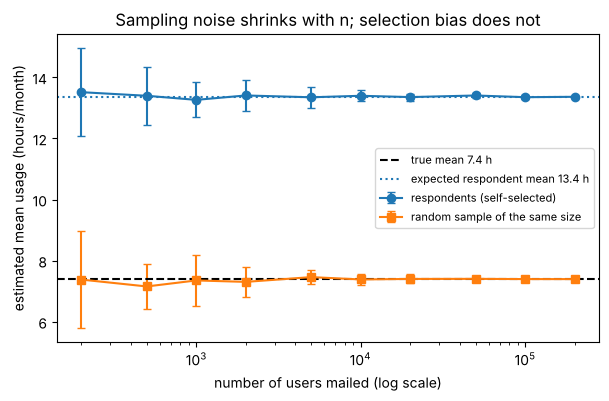

mailed     200: respondents  13.52 +/- 1.44    random sample  7.38 +/- 1.59    truth 7.4
mailed    5000: respondents  13.35 +/- 0.34    random sample  7.46 +/- 0.23    truth 7.4
mailed  200000: respondents  13.36 +/- 0.04    random sample  7.40 +/- 0.04    truth 7.4


In [3]:
def mail_survey(n_mailed, rng, p_engaged=0.3, hours=(2.0, 20.0), response=(0.10, 0.40)):
    engaged = rng.random(n_mailed) < p_engaged
    usage = np.where(engaged, hours[1], hours[0]) + rng.normal(0, 0.5, n_mailed)
    responds = rng.random(n_mailed) < np.where(engaged, response[1], response[0])
    k = responds.sum()                                      # number of respondents
    random_subset = rng.choice(n_mailed, size=k, replace=False)   # a random sample of the same size
    return usage[responds].mean(), usage[random_subset].mean()

true_mean = 0.7 * 2.0 + 0.3 * 20.0
expected_biased = (0.7 * 0.10 * 2.0 + 0.3 * 0.40 * 20.0) / (0.7 * 0.10 + 0.3 * 0.40)
sizes = np.array([200, 500, 1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000])
reps = 30
biased = np.array([[mail_survey(m, rng)[0] for _ in range(reps)] for m in sizes])
random_ = np.array([[mail_survey(m, rng)[1] for _ in range(reps)] for m in sizes])

plt.errorbar(sizes, biased.mean(1), yerr=biased.std(1), fmt="o-", capsize=3, label="respondents (self-selected)")
plt.errorbar(sizes, random_.mean(1), yerr=random_.std(1), fmt="s-", capsize=3, label="random sample of the same size")
plt.axhline(true_mean, color="k", ls="--", label=f"true mean {true_mean} h")
plt.axhline(expected_biased, color="C0", ls=":", label=f"expected respondent mean {expected_biased:.1f} h")
plt.xscale("log"); plt.xlabel("number of users mailed (log scale)"); plt.ylabel("estimated mean usage (hours/month)")
plt.title("Sampling noise shrinks with n; selection bias does not"); plt.legend(fontsize=8); plt.show()

for m, b, r in zip(sizes[[0, 4, 9]], biased[[0, 4, 9]], random_[[0, 4, 9]]):
    print(f"mailed {m:>7d}: respondents {b.mean():6.2f} +/- {b.std():.2f}    random sample {r.mean():5.2f} +/- {r.std():.2f}    truth {true_mean}")

The error bars (one standard deviation over 30 repetitions) collapse as the mailing grows — that is the
$1/\sqrt{n}$ law. The random sample converges to 7.4; the respondents converge to 13.4, which is
exactly the $\frac{0.07 \times 2 + 0.12 \times 20}{0.19}$ the guide computes. Eighty percent too high,
with a tiny error bar: *precisely wrong*. A sample that is a thousand times larger buys nothing.

**Try it yourself:** set both response probabilities to 0.25 and re-run. Then make the casual users the
more likely responders. What determines the sign of the bias?

## 2. Descriptive statistics, robust and otherwise

Ten API response times in milliseconds, nine ordinary and one that hit a cold cache. We compute every
summary from Section 2 of the guide from scratch — mean, median, trimmed mean, both variances, quartiles,
IQR and MAD — and then check against NumPy and SciPy.

In [4]:
times = np.array([120, 135, 140, 150, 155, 160, 170, 180, 210, 2400], dtype=float)

def my_median(v):
    s = np.sort(v); n = len(s); m = n // 2
    return s[m] if n % 2 else 0.5 * (s[m - 1] + s[m])

def trimmed_mean(v, alpha):
    s = np.sort(v); k = int(np.floor(alpha * len(s)))          # drop k smallest and k largest
    return s[k:len(s) - k].mean()

def variance(v, ddof=0):
    return ((v - v.mean()) ** 2).sum() / (len(v) - ddof)

def quantile(v, q):                                            # linear interpolation, NumPy's default
    s = np.sort(v); pos = q * (len(s) - 1); lo = int(np.floor(pos)); hi = int(np.ceil(pos))
    return s[lo] + (pos - lo) * (s[hi] - s[lo])

def mad(v):
    return my_median(np.abs(v - my_median(v)))

rows = [
    ("mean",                times.mean(),                np.mean(times)),
    ("median",              my_median(times),            np.median(times)),
    ("10% trimmed mean",    trimmed_mean(times, 0.10),   stats.trim_mean(times, 0.10)),
    ("variance, divisor n", variance(times, 0),          np.var(times, ddof=0)),
    ("variance, divisor n-1", variance(times, 1),        np.var(times, ddof=1)),
    ("sd s (ddof=1)",       np.sqrt(variance(times, 1)), np.std(times, ddof=1)),
    ("Q1 (25%)",            quantile(times, 0.25),       np.quantile(times, 0.25)),
    ("Q3 (75%)",            quantile(times, 0.75),       np.quantile(times, 0.75)),
    ("IQR",                 quantile(times, 0.75) - quantile(times, 0.25), stats.iqr(times)),
    ("MAD",                 mad(times),                  stats.median_abs_deviation(times)),
    ("1.4826 * MAD",        1.4826 * mad(times),         stats.median_abs_deviation(times, scale="normal")),
]
print(f"{'statistic':24s}{'from scratch':>14s}{'library':>14s}")
for name, mine, lib in rows:
    print(f"{name:24s}{mine:14.3f}{lib:14.3f}")
clean = times[:-1]
print(f"\nwithout the outlier: mean {clean.mean():.1f}, sd {clean.std(ddof=1):.1f}  ->  the median, trimmed mean and scaled MAD were close; mean and sd were not")

statistic                 from scratch       library
mean                           382.000       382.000
median                         157.500       157.500
10% trimmed mean               162.500       162.500
variance, divisor n         453051.000    453051.000
variance, divisor n-1       503390.000    503390.000
sd s (ddof=1)                  709.500       709.500
Q1 (25%)                       142.500       142.500
Q3 (75%)                       177.500       177.500
IQR                             35.000        35.000
MAD                             20.000        20.000
1.4826 * MAD                    29.652        29.652

without the outlier: mean 157.8, sd 26.7  ->  the median, trimmed mean and scaled MAD were close; mean and sd were not


### Shape: histogram, kernel density estimate and empirical CDF

For shape we need more than ten points. We generate 200 latencies from a log-normal distribution (a
realistic right-skewed model: median 150 ms, $\sigma = 0.6$ on the log scale) with its own seeded
generator so the same sample can be reused in the bootstrap section. The KDE is
$\hat f(x) = \frac{1}{nh}\sum_i K\!\big(\frac{x - x_i}{h}\big)$ with a Gaussian kernel and Silverman's
bandwidth $h = 0.9\min(s, \text{IQR}/1.34)\,n^{-1/5}$; the ECDF is $\hat F_n(x) = \frac1n\sum_i \mathbf 1[x_i \le x]$.

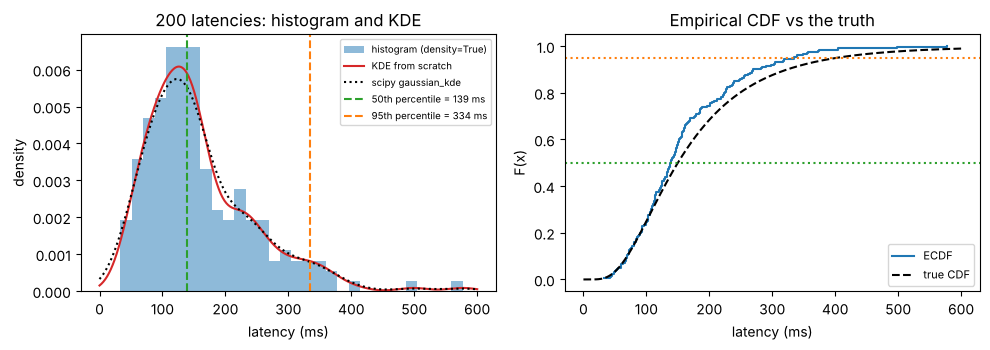

mean 158.7   median 138.7   p95 334.3   sd 86.9   (true median 150, true mean 179.6)


In [5]:
lat_rng = np.random.default_rng(7)
latency = lat_rng.lognormal(mean=np.log(150), sigma=0.6, size=200)
n_lat = len(latency)

def kde(data, grid):
    s = data.std(ddof=1); iqr_ = np.subtract(*np.quantile(data, [0.75, 0.25]))
    h = 0.9 * min(s, iqr_ / 1.34) * len(data) ** (-1 / 5)                 # Silverman's rule of thumb
    return np.exp(-0.5 * ((grid[:, None] - data[None, :]) / h) ** 2).sum(1) / (len(data) * h * np.sqrt(2 * np.pi))

grid = np.linspace(0, 600, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.hist(latency, bins=30, density=True, alpha=0.5, label="histogram (density=True)")
ax1.plot(grid, kde(latency, grid), "C3", label="KDE from scratch")
ax1.plot(grid, stats.gaussian_kde(latency)(grid), "k:", label="scipy gaussian_kde")
for q, c in [(0.5, "C2"), (0.95, "C1")]:
    ax1.axvline(np.quantile(latency, q), color=c, ls="--", label=f"{int(q*100)}th percentile = {np.quantile(latency, q):.0f} ms")
ax1.set_xlabel("latency (ms)"); ax1.set_ylabel("density"); ax1.set_title("200 latencies: histogram and KDE"); ax1.legend(fontsize=7)

xs = np.sort(latency); ecdf = np.arange(1, n_lat + 1) / n_lat
ax2.step(xs, ecdf, where="post", label="ECDF")
ax2.plot(grid, stats.lognorm.cdf(grid, s=0.6, scale=150), "k--", label="true CDF")
ax2.axhline(0.5, color="C2", ls=":"); ax2.axhline(0.95, color="C1", ls=":")
ax2.set_xlabel("latency (ms)"); ax2.set_ylabel("F(x)"); ax2.set_title("Empirical CDF vs the truth"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"mean {latency.mean():.1f}   median {np.median(latency):.1f}   p95 {np.quantile(latency, 0.95):.1f}   sd {latency.std(ddof=1):.1f}   (true median 150, true mean {150*np.exp(0.18):.1f})")

In [6]:
# breakdown points: move k of the nine clean response times to a huge value
for k in range(0, 6):
    v = clean.copy(); v[:k] = 1e6
    print(f"{k} of 9 corrupted:  mean {v.mean():>10.1f}   sd {v.std(ddof=1):>10.1f}   median {my_median(v):>9.1f}   MAD {mad(v):>7.1f}   10%-trimmed {trimmed_mean(v, 0.1):>10.1f}   20%-trimmed {trimmed_mean(v, 0.2):>10.1f}")

0 of 9 corrupted:  mean      157.8   sd       26.7   median     155.0   MAD    15.0   10%-trimmed      157.8   20%-trimmed      155.7
1 of 9 corrupted:  mean   111255.6   sd   333279.2   median     160.0   MAD    20.0   10%-trimmed   111255.6   20%-trimmed      166.4
2 of 9 corrupted:  mean   222351.7   sd   440885.2   median     170.0   MAD    20.0   10%-trimmed   222351.7   20%-trimmed   143003.6
3 of 9 corrupted:  mean   333447.2   sd   499914.6   median     180.0   MAD    30.0   10%-trimmed   333447.2   20%-trimmed   285839.3
4 of 9 corrupted:  mean   444541.7   sd   526954.0   median     210.0   MAD    55.0   10%-trimmed   444541.7   20%-trimmed   428674.3
5 of 9 corrupted:  mean   555635.6   sd   526951.4   median 1000000.0   MAD     0.0   10%-trimmed   555635.6   20%-trimmed   571508.6


One corrupted value wrecks the mean and the standard deviation (breakdown point 0). The 10%-trimmed mean
trims $\lfloor 0.1 \times 9 \rfloor = 0$ values per side, so at $n = 9$ it *is* the mean and fails just as
fast; the 20%-trimmed mean trims one value per side and survives exactly one corrupted point (breakdown
point $\alpha$). The median and the MAD survive four corrupted values out of nine and break at five —
their 50% breakdown point. The ECDF needs no bins or bandwidth and converges uniformly to the true CDF;
the KDE depends on $h$ (set it to 5 or 60 in `kde` to see too spiky and too smooth), the histogram on
the bin edges.

## 3. Estimators are random variables: mean vs median, and three variance estimators

For $n = 25$ observations we compare the sample mean and the sample median as estimators of the centre,
for a Normal and for a (heavy-tailed) Laplace population, by drawing 20,000 samples of each. The guide
predicts $\operatorname{Var}(\text{median}) / \operatorname{Var}(\bar X) \approx \pi/2 \approx 1.57$ for
normal data and $\approx 1/2$ for Laplace data.

Normal(0, 1)   Var(mean) 0.0401 (theory sigma^2/n = 0.0400)   Var(median) 0.0617   ratio median/mean = 1.54   bias of mean -0.0016, of median -0.0023


Laplace(0, 1)  Var(mean) 0.0808 (theory sigma^2/n = 0.0800)   Var(median) 0.0532   ratio median/mean = 0.66   bias of mean +0.0010, of median +0.0006


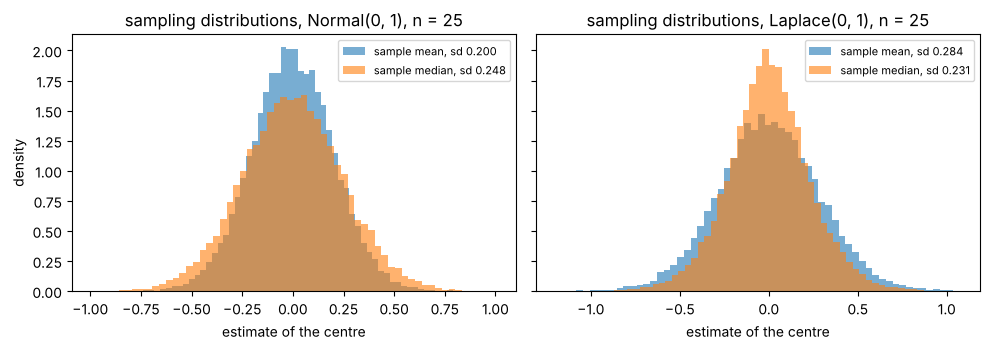

theory: pi/2 = 1.57 for normal data; the median is about twice as efficient for Laplace data


In [7]:
n, reps = 25, 20_000
populations = {"Normal(0, 1)": (rng.normal(0, 1, size=(reps, n)), 1.0),
               "Laplace(0, 1)": (rng.laplace(0, 1, size=(reps, n)), 2.0)}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, (X, var_pop)) in zip(axes, populations.items()):
    xbar, med = X.mean(1), np.median(X, 1)
    ax.hist(xbar, bins=60, alpha=0.6, density=True, label=f"sample mean, sd {xbar.std():.3f}")
    ax.hist(med, bins=60, alpha=0.6, density=True, label=f"sample median, sd {med.std():.3f}")
    ax.set_title(f"sampling distributions, {name}, n = {n}"); ax.set_xlabel("estimate of the centre"); ax.legend(fontsize=8)
    print(f"{name:14s} Var(mean) {xbar.var():.4f} (theory sigma^2/n = {var_pop/n:.4f})   Var(median) {med.var():.4f}   "
          f"ratio median/mean = {med.var()/xbar.var():.2f}   bias of mean {xbar.mean():+.4f}, of median {med.mean():+.4f}")
axes[0].set_ylabel("density"); plt.tight_layout(); plt.show()
print(f"theory: pi/2 = {np.pi/2:.2f} for normal data; the median is about twice as efficient for Laplace data")

Both estimators are unbiased in both cases (the histograms are centred on 0). For normal data the median
is wider — you would need about 57% more observations to match the mean. For Laplace data the picture
flips: the median is the tighter one. *Which estimator is better depends on the population's tails.*

### Bias, variance and MSE of three variance estimators

$\hat\sigma^2_c = c\sum_i (X_i - \bar X)^2$ with $c = \frac{1}{n-1}, \frac1n, \frac1{n+1}$ for $n = 10$
normal observations with $\sigma^2 = 1$. Since $\sum_i (X_i - \bar X)^2 \sim \chi^2_{9}$ has mean 9 and
variance 18, the theory is $\text{bias} = 9c - 1$ and $\text{variance} = 18c^2$.

In [8]:
n, reps = 10, 50_000
X = rng.normal(0, 1, size=(reps, n))
ss = ((X - X.mean(1, keepdims=True)) ** 2).sum(1)              # sum of squared deviations, one per sample
print(f"{'divisor':8s}{'bias':>9s}{'theory':>9s}{'variance':>10s}{'theory':>9s}{'MSE':>9s}{'bias^2+var':>12s}")
for name, c in [("n-1", 1 / (n - 1)), ("n", 1 / n), ("n+1", 1 / (n + 1))]:
    est = c * ss
    bias, var, mse = est.mean() - 1.0, est.var(), ((est - 1.0) ** 2).mean()
    print(f"{name:8s}{bias:9.4f}{(n-1)*c - 1:9.4f}{var:10.4f}{2*(n-1)*c**2:9.4f}{mse:9.4f}{bias**2 + var:12.4f}")
print("\nunbiased (n-1) has the largest MSE; shrinking towards 0 (n+1) trades a little bias for less variance")

divisor      bias   theory  variance   theory      MSE  bias^2+var
n-1        0.0031   0.0000    0.2252   0.2222   0.2252      0.2252
n         -0.0973  -0.1000    0.1824   0.1800   0.1918      0.1918
n+1       -0.1793  -0.1818    0.1507   0.1488   0.1829      0.1829

unbiased (n-1) has the largest MSE; shrinking towards 0 (n+1) trades a little bias for less variance


### Shrinkage in many dimensions: the James–Stein estimator

Observe one noisy vector $X \sim \mathcal N(\theta, I_p)$ with $p = 10$. The obvious estimate is
$\hat\theta = X$ (total MSE $= p = 10$). James–Stein shrinks it toward the origin,
$\hat\theta_{JS} = \big(1 - \frac{p-2}{\|X\|^2}\big)X$, and the guide claims it wins for *every* $\theta$.
We check it along a range of $\|\theta\|$.

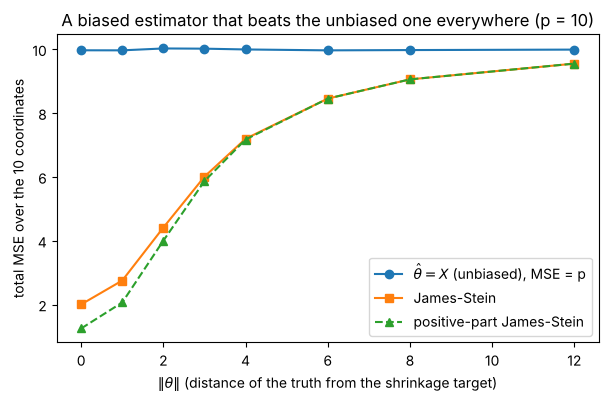

||theta|| =  0.0:  MSE(X) =   9.97   MSE(JS) =  2.00
||theta|| =  1.0:  MSE(X) =   9.96   MSE(JS) =  2.75
||theta|| =  2.0:  MSE(X) =  10.02   MSE(JS) =  4.41
||theta|| =  3.0:  MSE(X) =  10.02   MSE(JS) =  6.01
||theta|| =  4.0:  MSE(X) =   9.99   MSE(JS) =  7.19
||theta|| =  6.0:  MSE(X) =   9.96   MSE(JS) =  8.45
||theta|| =  8.0:  MSE(X) =   9.97   MSE(JS) =  9.05
||theta|| = 12.0:  MSE(X) =   9.99   MSE(JS) =  9.55


In [9]:
p, reps = 10, 20_000
norms = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0])
mse_mle, mse_js, mse_js_plus = [], [], []
for r in norms:
    theta = np.zeros(p); theta[0] = r                           # only ||theta|| matters, by symmetry
    X = theta + rng.normal(size=(reps, p))
    shrink = 1 - (p - 2) / (X ** 2).sum(1, keepdims=True)
    js = shrink * X
    js_plus = np.maximum(shrink, 0) * X                         # positive-part James-Stein: never flip the sign
    mse_mle.append(((X - theta) ** 2).sum(1).mean())
    mse_js.append(((js - theta) ** 2).sum(1).mean())
    mse_js_plus.append(((js_plus - theta) ** 2).sum(1).mean())

plt.plot(norms, mse_mle, "o-", label=r"$\hat\theta = X$ (unbiased), MSE = p")
plt.plot(norms, mse_js, "s-", label="James-Stein")
plt.plot(norms, mse_js_plus, "^--", label="positive-part James-Stein")
plt.xlabel(r"$\|\theta\|$ (distance of the truth from the shrinkage target)"); plt.ylabel("total MSE over the 10 coordinates")
plt.title("A biased estimator that beats the unbiased one everywhere (p = 10)"); plt.legend(); plt.show()
for r, a, b in zip(norms, mse_mle, mse_js):
    print(f"||theta|| = {r:4.1f}:  MSE(X) = {a:6.2f}   MSE(JS) = {b:5.2f}")

At $\theta = 0$ the shrinkage estimator has MSE about 2 instead of 10; far from the origin the gain fades
but never becomes a loss. This is the mathematical ancestor of ridge regression and weight decay
([Module 13](../../part-5-learning-theory/13-linear-models-and-regularization/README.md)): accept a
little bias, remove a lot of variance.

**Try it yourself:** set `p = 2` (where the theorem no longer applies) — does James–Stein still win?

## 4. Sampling distributions and the standard error

The sample mean of $n$ i.i.d. observations has standard deviation — the **standard error** —
$\sigma/\sqrt n$; a sample proportion has $\sqrt{p(1-p)/n}$. We draw from a very skewed population,
$\text{Exp}(1)$, to see two things at once: the sampling distribution becomes normal as $n$ grows (the
CLT), and its width follows the formula exactly.

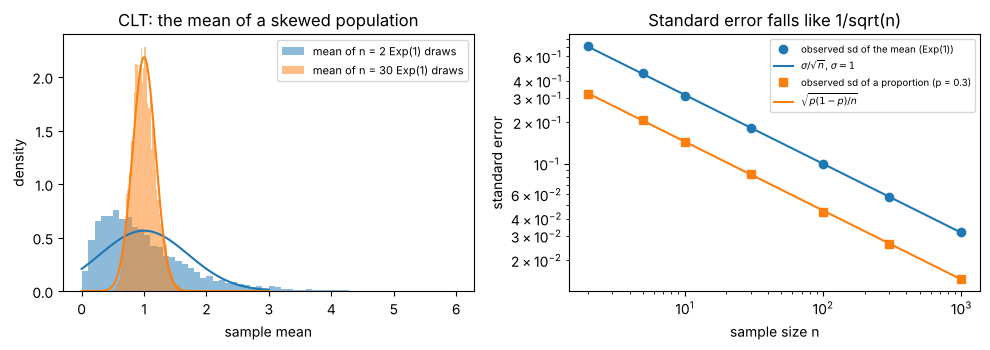

n =     2: sd(mean) 0.7131 vs 0.7071     sd(proportion) 0.3205 vs 0.3240
n =     5: sd(mean) 0.4519 vs 0.4472     sd(proportion) 0.2063 vs 0.2049
n =    10: sd(mean) 0.3116 vs 0.3162     sd(proportion) 0.1448 vs 0.1449
n =    30: sd(mean) 0.1820 vs 0.1826     sd(proportion) 0.0838 vs 0.0837
n =   100: sd(mean) 0.0999 vs 0.1000     sd(proportion) 0.0450 vs 0.0458
n =   300: sd(mean) 0.0573 vs 0.0577     sd(proportion) 0.0263 vs 0.0265
n =  1000: sd(mean) 0.0319 vs 0.0316     sd(proportion) 0.0145 vs 0.0145


In [10]:
ns = np.array([2, 5, 10, 30, 100, 300, 1_000])
reps, p_true = 5_000, 0.3
sd_mean = np.array([rng.exponential(1.0, size=(reps, m)).mean(1).std() for m in ns])
sd_prop = np.array([(rng.random(size=(reps, m)) < p_true).mean(1).std() for m in ns])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
grid = np.linspace(0, 3, 300)
for m, c in [(2, "C0"), (30, "C1")]:
    xb = rng.exponential(1.0, size=(reps, m)).mean(1)
    ax1.hist(xb, bins=60, density=True, alpha=0.5, color=c, label=f"mean of n = {m} Exp(1) draws")
    ax1.plot(grid, stats.norm.pdf(grid, 1, 1 / np.sqrt(m)), color=c, lw=1.5)
ax1.set_xlabel("sample mean"); ax1.set_ylabel("density"); ax1.set_title("CLT: the mean of a skewed population"); ax1.legend(fontsize=8)
ax2.loglog(ns, sd_mean, "o", label="observed sd of the mean (Exp(1))")
ax2.loglog(ns, 1 / np.sqrt(ns), "C0-", label=r"$\sigma/\sqrt{n}$, $\sigma = 1$")
ax2.loglog(ns, sd_prop, "s", color="C1", label=f"observed sd of a proportion (p = {p_true})")
ax2.loglog(ns, np.sqrt(p_true * (1 - p_true) / ns), "C1-", label=r"$\sqrt{p(1-p)/n}$")
ax2.set_xlabel("sample size n"); ax2.set_ylabel("standard error"); ax2.set_title("Standard error falls like 1/sqrt(n)"); ax2.legend(fontsize=7)
plt.tight_layout(); plt.show()
for m, a, b in zip(ns, sd_mean, sd_prop):
    print(f"n = {m:>5d}: sd(mean) {a:.4f} vs {1/np.sqrt(m):.4f}     sd(proportion) {b:.4f} vs {np.sqrt(p_true*(1-p_true)/m):.4f}")

In [11]:
# the poll and the filling machine from the guide, plus scipy's standard error of the mean
p_hat, n_poll = 0.52, 1_000
se_p = np.sqrt(p_hat * (1 - p_hat) / n_poll)
print(f"poll: p_hat = {p_hat}, n = {n_poll}:  SE = {se_p:.4f},  95% margin = {1.96*se_p:.3f}   (the famous +/- 3 points)")
print(f"      the LEAD 2p-1 = {2*p_hat-1:.2f} has SE {2*se_p:.4f} and margin +/- {2*1.96*se_p:.3f}  -> a 52-48 lead is ~1.3 SE from a tie")

sigma_fill, target = 4.0, 500.0
for n_pack, xbar_ in [(16, 497.5), (4, 497.5)]:
    se = sigma_fill / np.sqrt(n_pack); zscore = (xbar_ - target) / se
    print(f"filling machine: n = {n_pack:2d}, xbar = {xbar_}: SE = {se:.2f} g, z = {zscore:+.2f},  P(|Xbar - 500| >= {target-xbar_}) = {2*stats.norm.sf(abs(zscore)):.4f}")

print(f"\nscipy.stats.sem(latency) = {stats.sem(latency):.3f}   by hand s/sqrt(n) = {latency.std(ddof=1)/np.sqrt(n_lat):.3f}")
print(f"sd of the 200 latencies = {latency.std(ddof=1):.1f} ms (spread of individual requests; does not shrink with n)")

poll: p_hat = 0.52, n = 1000:  SE = 0.0158,  95% margin = 0.031   (the famous +/- 3 points)
      the LEAD 2p-1 = 0.04 has SE 0.0316 and margin +/- 0.062  -> a 52-48 lead is ~1.3 SE from a tie
filling machine: n = 16, xbar = 497.5: SE = 1.00 g, z = -2.50,  P(|Xbar - 500| >= 2.5) = 0.0124
filling machine: n =  4, xbar = 497.5: SE = 2.00 g, z = -1.25,  P(|Xbar - 500| >= 2.5) = 0.2113

scipy.stats.sem(latency) = 6.143   by hand s/sqrt(n) = 6.143
sd of the 200 latencies = 86.9 ms (spread of individual requests; does not shrink with n)


Even for $n = 2$ draws from an exponential the formula $\sigma/\sqrt n$ is exact — it is only the *shape*
that needs the CLT, and by $n = 30$ the histogram is close to the normal curve. In the right panel the
points sit on the theory lines across three decades of $n$: a straight line of slope $-1/2$ on log–log
axes. Keep the two numbers at the end apart: the standard deviation (87 ms) describes requests, the
standard error (6 ms) describes our knowledge of the mean.

## 5. Confidence intervals: a coverage experiment

A 95% interval is a *procedure* that captures the parameter in 95% of repeated samples. We test three
procedures on 10,000 samples of $n = 5$ from $\mathcal N(10, 2^2)$: the $z$-interval with $\sigma$ known,
the $t$-interval with $s$ estimated, and the common mistake — a $z$-interval that plugs in $s$. The guide
predicts the last one covers only $2\,F_{t_4}(1.96) - 1 \approx 88\%$ at $n = 5$.

n = 5: z_0.975 = 1.960, t_(4, 0.975) = 2.776
z, sigma known           coverage 0.9484   mean width 3.506
t, s estimated           coverage 0.9492   mean width 4.666
z with s  (too narrow)   coverage 0.8739   mean width 3.294
theory for 'z with s' at n = 5: 2 F_t4(1.96) - 1 = 0.8784


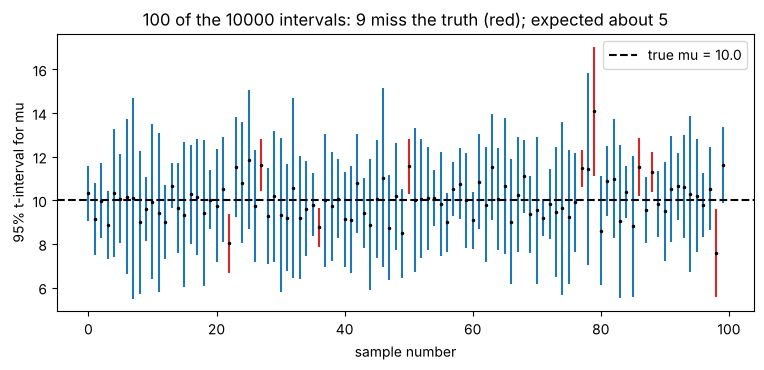

In [12]:
mu, sigma, n, reps = 10.0, 2.0, 5, 10_000
X = rng.normal(mu, sigma, size=(reps, n))
xbar, s = X.mean(1), X.std(1, ddof=1)
z = stats.norm.ppf(0.975); t = stats.t.ppf(0.975, df=n - 1)
intervals = {
    "z, sigma known":        (xbar - z * sigma / np.sqrt(n), xbar + z * sigma / np.sqrt(n)),
    "t, s estimated":        (xbar - t * s / np.sqrt(n),     xbar + t * s / np.sqrt(n)),
    "z with s  (too narrow)": (xbar - z * s / np.sqrt(n),     xbar + z * s / np.sqrt(n)),
}
print(f"n = {n}: z_0.975 = {z:.3f}, t_(4, 0.975) = {t:.3f}")
for name, (lo, hi) in intervals.items():
    covered = (lo <= mu) & (mu <= hi)
    print(f"{name:24s} coverage {covered.mean():.4f}   mean width {np.mean(hi - lo):.3f}")
print(f"theory for 'z with s' at n = 5: 2 F_t4(1.96) - 1 = {2*stats.t.cdf(z, df=n-1) - 1:.4f}")

lo, hi = intervals["t, s estimated"]; k = 100
covered = (lo[:k] <= mu) & (mu <= hi[:k])
plt.figure(figsize=(9, 3.6))
plt.vlines(np.arange(k), lo[:k], hi[:k], colors=np.where(covered, "C0", "C3"), lw=1.5)
plt.plot(np.arange(k), xbar[:k], "k.", ms=3)
plt.axhline(mu, color="k", ls="--", label=f"true mu = {mu}")
plt.xlabel("sample number"); plt.ylabel("95% t-interval for mu")
plt.title(f"100 of the {reps} intervals: {int((~covered).sum())} miss the truth (red); expected about 5")
plt.legend(); plt.show()

The $z$-interval with known $\sigma$ and the $t$-interval both hit 95% (within Monte Carlo error); the
$z$-with-$s$ interval is about 30% narrower than the $t$-interval and misses the truth about 12–13% of
the time. Each red segment is an interval that was computed correctly and is nevertheless wrong — the
95% belongs to the procedure, not to any one of them.

**Try it yourself:** change `n` to 30. The three procedures should become nearly indistinguishable — why?

### Wald vs Wilson for a proportion: exact coverage

For a proportion we do not need to simulate: $\hat p = k/n$ takes only $n + 1$ values, so the coverage
of any interval at a given $p$ is $\sum_{k} P(K = k)\,\mathbf 1[\text{interval}(k, n) \ni p]$. We compute
it for $p = 0.05$ (rare events) and $p = 0.5$ as a function of $n$.

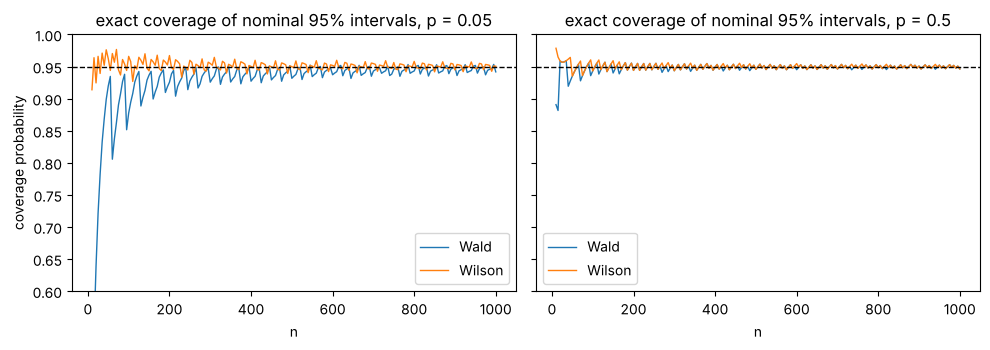

p = 0.05, n =   20: Wald 0.639   Wilson 0.925
p = 0.05, n =   50: Wald 0.920   Wilson 0.962
p = 0.05, n =  100: Wald 0.877   Wilson 0.966
p = 0.05, n =  200: Wald 0.926   Wilson 0.967
p = 0.05, n =  500: Wald 0.932   Wilson 0.950
p = 0.05, n = 1000: Wald 0.942   Wilson 0.950

k =  9/200  Wald [+0.0163, 0.0737]   Wilson [0.0239, 0.0833]   scipy wilson [0.0239, 0.0833]
k =  0/20   Wald [+0.0000, 0.0000]   Wilson [0.0000, 0.1611]   scipy wilson [0.0000, 0.1611]
k =  2/150  Wald [-0.0050, 0.0317]   Wilson [0.0037, 0.0473]   scipy wilson [0.0037, 0.0473]
rule of three for 0/20: 3/n = 0.150   Wilson upper limit z^2/(n+z^2) = 0.161


In [13]:
def wald_ci(k, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); p = k / n
    h = z * np.sqrt(p * (1 - p) / n)
    return p - h, p + h

def wilson_ci(k, n, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2); p = k / n; z2 = z * z
    centre = (p + z2 / (2 * n)) / (1 + z2 / n)
    half = z / (1 + z2 / n) * np.sqrt(p * (1 - p) / n + z2 / (4 * n * n))
    return centre - half, centre + half

def exact_coverage(ci_fn, n, p, conf=0.95):
    ks = np.arange(n + 1); pmf = stats.binom.pmf(ks, n, p)
    lo, hi = ci_fn(ks, n, conf)
    return pmf[(lo <= p) & (p <= hi)].sum()

ns = np.arange(10, 1001, 5)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, p in zip(axes, (0.05, 0.5)):
    ax.plot(ns, [exact_coverage(wald_ci, m, p) for m in ns], label="Wald", lw=1)
    ax.plot(ns, [exact_coverage(wilson_ci, m, p) for m in ns], label="Wilson", lw=1)
    ax.axhline(0.95, color="k", ls="--", lw=1); ax.set_ylim(0.6, 1.0)
    ax.set_xlabel("n"); ax.set_title(f"exact coverage of nominal 95% intervals, p = {p}"); ax.legend()
axes[0].set_ylabel("coverage probability"); plt.tight_layout(); plt.show()

for m in (20, 50, 100, 200, 500, 1000):
    print(f"p = 0.05, n = {m:>4d}: Wald {exact_coverage(wald_ci, m, 0.05):.3f}   Wilson {exact_coverage(wilson_ci, m, 0.05):.3f}")

print()
for k, m in [(9, 200), (0, 20), (2, 150)]:
    sp = stats.binomtest(k, m).proportion_ci(confidence_level=0.95, method="wilson")
    print(f"k = {k:>2d}/{m:<4d} Wald [{wald_ci(k, m)[0]:+.4f}, {wald_ci(k, m)[1]:.4f}]   Wilson [{wilson_ci(k, m)[0]:.4f}, {wilson_ci(k, m)[1]:.4f}]"
          f"   scipy wilson [{sp.low:.4f}, {sp.high:.4f}]")
print(f"rule of three for 0/20: 3/n = {3/20:.3f}   Wilson upper limit z^2/(n+z^2) = {z*z/(20+z*z):.3f}")

For $p = 0.05$ the Wald interval's coverage oscillates far below 95% — at $n = 20$ it is 64%, and it
does not settle near the nominal level until $n$ is around 1,000 — while Wilson stays close to 95%
throughout. At $p = 0.5$ the two are nearly identical and both fine: the Wald interval is not wrong,
it is wrong *near the boundaries*. With $k = 0$ it has zero width, and for $2/150$ its lower limit is
negative; Wilson's never leaves $[0, 1]$. The hand-written Wilson formula matches `scipy.stats.binomtest`.

## 6. The bootstrap, from scratch

There is no standard-error formula for a median or a 95th percentile that works well at $n = 200$. So we
resample: draw 200 values *with replacement* from the 200 latencies of Section 2, compute the statistic,
repeat $B = 10{,}000$ times. The spread of the replicates estimates the standard error, and their 2.5%
and 97.5% quantiles form the **percentile interval**. We also bootstrap the mean, where we *can* check
the answer against $s/\sqrt n$ and the $t$-interval.

mean             estimate  158.7 ms   bootstrap SE  6.16   95% percentile CI [ 146.9,  171.0]
median           estimate  138.7 ms   bootstrap SE  5.16   95% percentile CI [ 128.2,  148.4]
95th percentile  estimate  334.3 ms   bootstrap SE 18.59   95% percentile CI [ 290.0,  356.4]

check on the mean: formula SE s/sqrt(n) = 6.14,  t-interval [146.6, 170.8]
each resample leaves out on average 0.366 of the data   (theory (1 - 1/n)^n = 0.367)


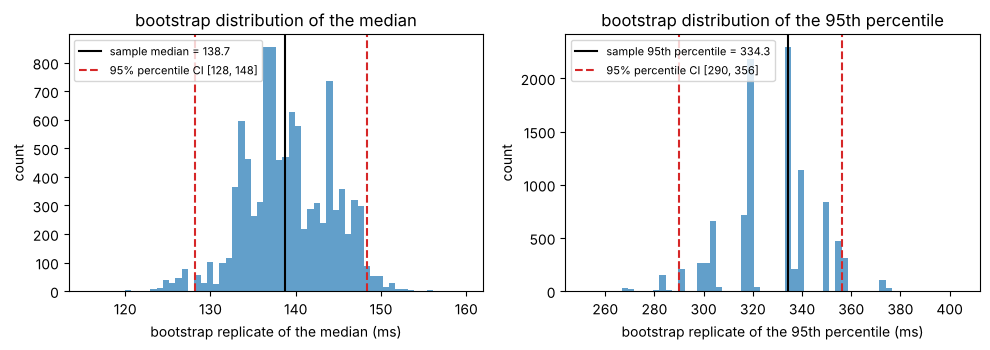

scipy.stats.bootstrap, median: [128.2, 148.4],  SE 5.12


In [14]:
boot_rng = np.random.default_rng(0)
B = 10_000
idx = boot_rng.integers(0, n_lat, size=(B, n_lat))             # B bootstrap samples, as index arrays
resamples = latency[idx]                                        # shape (B, n): each row is one resample

def percentile_ci(replicates, conf=0.95):
    return np.quantile(replicates, [(1 - conf) / 2, (1 + conf) / 2])

statistics = {"mean": (resamples.mean(1), latency.mean()),
              "median": (np.median(resamples, axis=1), np.median(latency)),
              "95th percentile": (np.quantile(resamples, 0.95, axis=1), np.quantile(latency, 0.95))}
for name, (reps_, point) in statistics.items():
    lo, hi = percentile_ci(reps_)
    print(f"{name:16s} estimate {point:6.1f} ms   bootstrap SE {reps_.std(ddof=1):5.2f}   95% percentile CI [{lo:6.1f}, {hi:6.1f}]")
t199 = stats.t.ppf(0.975, df=n_lat - 1); se_formula = latency.std(ddof=1) / np.sqrt(n_lat)
print(f"\ncheck on the mean: formula SE s/sqrt(n) = {se_formula:.2f},  t-interval [{latency.mean() - t199*se_formula:.1f}, {latency.mean() + t199*se_formula:.1f}]")
print(f"each resample leaves out on average {np.mean([len(np.setdiff1d(np.arange(n_lat), row)) for row in idx[:500]]) / n_lat:.3f} of the data   (theory (1 - 1/n)^n = {(1 - 1/n_lat)**n_lat:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ("median", "95th percentile")):
    reps_, point = statistics[name]; lo, hi = percentile_ci(reps_)
    ax.hist(reps_, bins=60, alpha=0.7)
    ax.axvline(point, color="k", label=f"sample {name} = {point:.1f}")
    ax.axvline(lo, color="C3", ls="--", label=f"95% percentile CI [{lo:.0f}, {hi:.0f}]"); ax.axvline(hi, color="C3", ls="--")
    ax.set_xlabel(f"bootstrap replicate of the {name} (ms)"); ax.set_ylabel("count"); ax.set_title(f"bootstrap distribution of the {name}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# the same thing with scipy (different random stream, so expect agreement up to Monte Carlo error)
res = stats.bootstrap((latency,), np.median, confidence_level=0.95, n_resamples=B, method="percentile", random_state=1)
print(f"scipy.stats.bootstrap, median: [{res.confidence_interval.low:.1f}, {res.confidence_interval.high:.1f}],  SE {res.standard_error:.2f}")

For the mean the bootstrap reproduces the formula (SE 6.2 vs 6.1 ms, interval matching the $t$-interval
to within a millisecond) — reassuring, and a good unit test for bootstrap code. For the median and the
95th percentile it produces intervals that no formula in this module could. Notice the p95 histogram:
lumpy and more than three times wider than the median's, because a 95th percentile of 200 values is
decided by the ten largest observations. The bootstrap distribution also reveals skew — the interval for the
median is not symmetric around the estimate.

### A statistic of pairs, and a statistic where the bootstrap fails

For a correlation coefficient the resampling unit is the *pair* $(x_i, y_i)$ — resampling $x$ and $y$
separately would destroy the very thing being measured. We compare the bootstrap interval with the
classical Fisher-$z$ interval $\tanh\big(\operatorname{artanh}(r) \pm 1.96/\sqrt{n-3}\big)$. Then we
bootstrap the sample **maximum** of 50 uniform draws and compare with the true sampling distribution,
which we know because we know the population.

correlation: r = 0.665 (true rho = 0.6)   bootstrap SE 0.079   percentile CI [0.500, 0.810]   Fisher-z CI [0.475, 0.796]


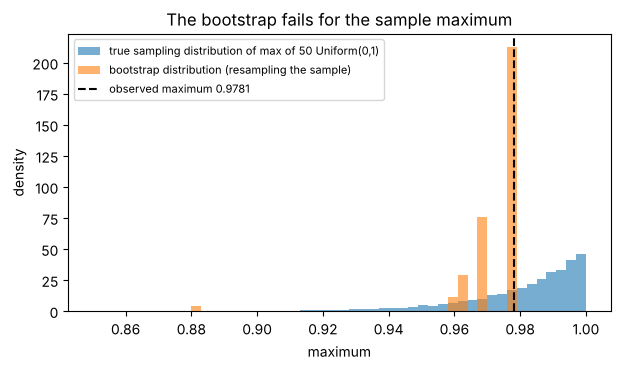

fraction of bootstrap maxima equal to the observed maximum: 0.638   (theory 1 - (1 - 1/50)^50 = 0.636)
true sampling sd of the max 0.0193   bootstrap sd 0.0127   -> wrong shape, wrong width, and the bootstrap can never exceed the observed max


In [15]:
n_pairs, rho = 50, 0.6
Z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=n_pairs)
r_hat = np.corrcoef(Z[:, 0], Z[:, 1])[0, 1]
pair_idx = rng.integers(0, n_pairs, size=(B, n_pairs))
xs, ys = Z[pair_idx, 0], Z[pair_idx, 1]                          # resample PAIRS together
xs = xs - xs.mean(1, keepdims=True); ys = ys - ys.mean(1, keepdims=True)
r_boot = (xs * ys).sum(1) / np.sqrt((xs ** 2).sum(1) * (ys ** 2).sum(1))
fisher = np.tanh(np.arctanh(r_hat) + np.array([-1, 1]) * 1.96 / np.sqrt(n_pairs - 3))
print(f"correlation: r = {r_hat:.3f} (true rho = {rho})   bootstrap SE {r_boot.std(ddof=1):.3f}   percentile CI [{np.quantile(r_boot, 0.025):.3f}, {np.quantile(r_boot, 0.975):.3f}]"
      f"   Fisher-z CI [{fisher[0]:.3f}, {fisher[1]:.3f}]")

# the maximum: bootstrap distribution vs the true sampling distribution
u = rng.random(50); u_max = u.max()
true_max = rng.random(size=(B, 50)).max(1)                      # resample from the POPULATION (possible only in a simulation)
boot_max = u[rng.integers(0, 50, size=(B, 50))].max(1)          # resample from the SAMPLE
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(true_max, bins=50, range=(0.85, 1), alpha=0.6, density=True, label="true sampling distribution of max of 50 Uniform(0,1)")
ax.hist(boot_max, bins=50, range=(0.85, 1), alpha=0.6, density=True, label="bootstrap distribution (resampling the sample)")
ax.axvline(u_max, color="k", ls="--", label=f"observed maximum {u_max:.4f}")
ax.set_xlabel("maximum"); ax.set_ylabel("density"); ax.set_title("The bootstrap fails for the sample maximum"); ax.legend(fontsize=8); plt.show()
print(f"fraction of bootstrap maxima equal to the observed maximum: {(boot_max == u_max).mean():.3f}   (theory 1 - (1 - 1/50)^50 = {1 - (1 - 1/50)**50:.3f})")
print(f"true sampling sd of the max {true_max.std():.4f}   bootstrap sd {boot_max.std():.4f}   -> wrong shape, wrong width, and the bootstrap can never exceed the observed max")

The paired bootstrap for the correlation agrees with the Fisher interval to within a few hundredths,
without needing to know that $\operatorname{artanh}(r)$ is approximately normal. For the maximum the bootstrap distribution is a spike
at the observed value (63% of the replicates) with a left tail — nothing like the truth, which lives
mostly *above* the sample maximum. The plug-in principle fails because the maximum depends on the
extreme tail of $F$, where the empirical distribution is a poor substitute.

**Try it yourself:** increase `B` from 10,000 to 50,000 for the median — does the interval change much?
(It should not: the bootstrap's error is dominated by $n$, not by $B$.) Then try `n_lat = 20` latencies.

## 7. Sample-size planning

Invert the standard-error formulas: to estimate a mean to within $\pm e$ with confidence $1 - \alpha$,
$n \ge (z_{\alpha/2}\sigma/e)^2$; for a proportion, $n \ge z_{\alpha/2}^2\,p(1-p)/e^2$, with $p = 1/2$ as
the worst case. The cost of precision grows like $1/e^2$.

mean delivery time to +/- 2 min, sigma ~ 15: n = 217;  to +/- 1 min: 865
proportion to +/- 3 points, no prior guess:  n = 1068;  +/- 1 point: 9604;  at 99% confidence, +/- 3: 1844
conversion rate near 2% to +/- 1 point: n = 753 visitors per variant
distribution-free (Hoeffding) for +/- 3 points at 95%: n = 2050  vs CLT 1068

test-set size for a 95% interval on a model's accuracy:
  accuracy  +/- 5.0 pt  +/- 2.0 pt  +/- 1.0 pt  +/- 0.5 pt
      0.50         385       2,401       9,604      38,415
      0.70         323       2,017       8,068      32,269
      0.90         139         865       3,458      13,830
      0.95          73         457       1,825       7,299
      0.99          16          96         381       1,522


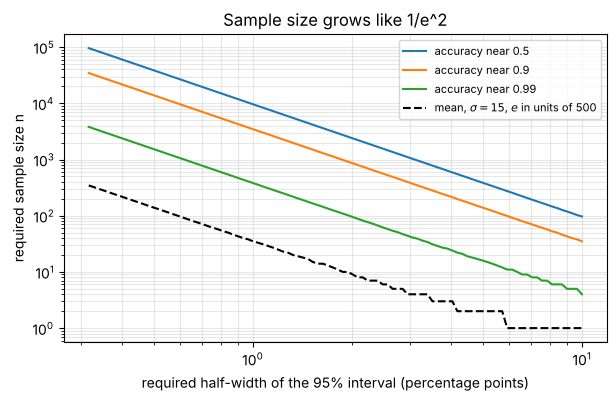

In [16]:
def n_for_mean(sigma, e, conf=0.95):
    z = stats.norm.ppf(0.5 + conf / 2)
    return int(np.ceil((z * sigma / e) ** 2))

def n_for_proportion(e, conf=0.95, p=0.5):
    z = stats.norm.ppf(0.5 + conf / 2)
    return int(np.ceil(z * z * p * (1 - p) / e ** 2))

print(f"mean delivery time to +/- 2 min, sigma ~ 15: n = {n_for_mean(15, 2)};  to +/- 1 min: {n_for_mean(15, 1)}")
print(f"proportion to +/- 3 points, no prior guess:  n = {n_for_proportion(0.03)};  +/- 1 point: {n_for_proportion(0.01)};  at 99% confidence, +/- 3: {n_for_proportion(0.03, conf=0.99)}")
print(f"conversion rate near 2% to +/- 1 point: n = {n_for_proportion(0.01, p=0.02)} visitors per variant")
print(f"distribution-free (Hoeffding) for +/- 3 points at 95%: n = {int(np.ceil(np.log(2/0.05) / (2 * 0.03**2)))}  vs CLT {n_for_proportion(0.03)}")

print("\ntest-set size for a 95% interval on a model's accuracy:")
margins = [0.05, 0.02, 0.01, 0.005]
print(f"{'accuracy':>10s}" + "".join(f"{'+/- ' + str(int(e*1000)/10) + ' pt':>12s}" for e in margins))
for acc in (0.5, 0.7, 0.9, 0.95, 0.99):
    print(f"{acc:10.2f}" + "".join(f"{n_for_proportion(e, p=acc):12,d}" for e in margins))

es = np.logspace(-2.5, -1, 100)
for acc in (0.5, 0.9, 0.99):
    plt.loglog(es * 100, [n_for_proportion(e, p=acc) for e in es], label=f"accuracy near {acc}")
plt.loglog(es * 100, [n_for_mean(15, e * 500) for e in es], "k--", label=r"mean, $\sigma = 15$, $e$ in units of 500")
plt.xlabel("required half-width of the 95% interval (percentage points)"); plt.ylabel("required sample size n")
plt.title("Sample size grows like 1/e^2"); plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.show()

Every line has slope $-2$ on log–log axes: a tenfold tighter interval costs a hundredfold more data.
Near 50% accuracy — the regime of hard benchmarks — a ± 1 point claim needs about 9,600 examples; a
100-prompt evaluation has a margin of about ± 10 points. Plan the test set *before* labelling.

## 8. A test-set accuracy is a sample proportion

We train two simple classifiers on half of `load_breast_cancer` (569 tumours, 30 features) and evaluate
on the other half ($n = 285$): a **nearest-centroid** classifier on standardised features, and a weaker
**one-feature threshold** on mean radius. For each accuracy we compute the formula standard error
$\sqrt{\hat a(1 - \hat a)/n}$, the Wilson interval and a bootstrap interval (resampling test *examples*),
and then compare the two models the right way — on their per-example disagreements.

In [17]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

X_all, y_all = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.5, random_state=0, stratify=y_all)
n_te = len(y_te)

# model A: nearest centroid on standardised features (statistics from the training half only)
mu_tr, sd_tr = X_tr.mean(0), X_tr.std(0)
Z_tr, Z_te = (X_tr - mu_tr) / sd_tr, (X_te - mu_tr) / sd_tr
c0, c1 = Z_tr[y_tr == 0].mean(0), Z_tr[y_tr == 1].mean(0)
pred_A = (((Z_te - c1) ** 2).sum(1) < ((Z_te - c0) ** 2).sum(1)).astype(int)

# model B: a single threshold on feature 0 (mean radius), chosen on the training half
cands = np.quantile(X_tr[:, 0], np.linspace(0.05, 0.95, 91))
train_acc = [((X_tr[:, 0] < c).astype(int) == y_tr).mean() for c in cands]
thr = cands[int(np.argmax(train_acc))]
pred_B = (X_te[:, 0] < thr).astype(int)

correct_A, correct_B = pred_A == y_te, pred_B == y_te
boot_idx = rng.integers(0, n_te, size=(10_000, n_te))
for name, correct in [("A: nearest centroid", correct_A), ("B: one-feature threshold", correct_B)]:
    acc = correct.mean(); se = np.sqrt(acc * (1 - acc) / n_te)
    lo_w, hi_w = wilson_ci(correct.sum(), n_te)
    boot_acc = correct[boot_idx].mean(1)
    print(f"{name:26s} accuracy {acc:.4f} = {correct.sum()}/{n_te}   SE {se:.4f}   Wilson [{lo_w:.3f}, {hi_w:.3f}]"
          f"   bootstrap [{np.quantile(boot_acc, 0.025):.3f}, {np.quantile(boot_acc, 0.975):.3f}]")

# paired comparison: only the disagreements carry information about the difference
n10 = int((correct_A & ~correct_B).sum()); n01 = int((~correct_A & correct_B).sum())
d = (n10 - n01) / n_te
se_paired = np.sqrt(((n10 + n01) / n_te - d ** 2) / n_te)
aA, aB = correct_A.mean(), correct_B.mean()
se_unpaired = np.sqrt(aA * (1 - aA) / n_te + aB * (1 - aB) / n_te)
boot_diff = (correct_A[boot_idx].astype(float) - correct_B[boot_idx]).mean(1)
print(f"\nA right & B wrong: {n10},  B right & A wrong: {n01},  agree on {n_te - n10 - n01} of {n_te}")
print(f"difference A - B = {d:+.4f}   paired SE {se_paired:.4f}  [{d - 1.96*se_paired:+.3f}, {d + 1.96*se_paired:+.3f}]"
      f"   paired bootstrap [{np.quantile(boot_diff, 0.025):+.3f}, {np.quantile(boot_diff, 0.975):+.3f}]")
print(f"unpaired SE (ignores that both models see the same examples) {se_unpaired:.4f} -> interval {se_unpaired/se_paired:.2f}x too wide")
print(f"for a +/- 2 point interval on A's accuracy you would need n = {n_for_proportion(0.02, p=aA)} test examples; on the difference n = {int(np.ceil(1.96**2 * ((n10 + n01)/n_te - d**2) / 0.02**2))}")

A: nearest centroid        accuracy 0.9193 = 262/285   SE 0.0161   Wilson [0.882, 0.946]   bootstrap [0.888, 0.947]
B: one-feature threshold   accuracy 0.8737 = 249/285   SE 0.0197   Wilson [0.830, 0.907]   bootstrap [0.835, 0.912]

A right & B wrong: 27,  B right & A wrong: 14,  agree on 244 of 285
difference A - B = +0.0456   paired SE 0.0223  [+0.002, +0.089]   paired bootstrap [+0.004, +0.088]
unpaired SE (ignores that both models see the same examples) 0.0254 -> interval 1.14x too wide
for a +/- 2 point interval on A's accuracy you would need n = 713 test examples; on the difference n = 1362


Both accuracies carry an SE of about 1.6–2 points on 285 examples, and the formula, Wilson and bootstrap
intervals agree. The difference between the models is estimated more precisely from the *paired* data
than the unpaired formula suggests, and the paired bootstrap confirms the paired formula. The last line
is the sobering one: to pin an accuracy down to ± 2 points needs several hundred more examples than we
have.

### The best of $k$ seeds is biased upward

Suppose $k$ training runs (or checkpoints, or hyper-parameter settings) all have the *same* true
accuracy 0.80 and are each scored on a validation set of 200 examples. Reporting the best one
overstates the truth by roughly $\operatorname{SE} \times \mathbb E[\max \text{ of } k \text{ standard normals}]$.

validation SE at accuracy 0.8, n = 200: 0.0283

   k   E[best score]  optimism   SE x E[max]
   1          0.8000   -0.0000        0.0000
   3          0.8238   +0.0238        0.0239
   5          0.8324   +0.0324        0.0329
  10          0.8424   +0.0424        0.0435


  24          0.8534   +0.0534        0.0551


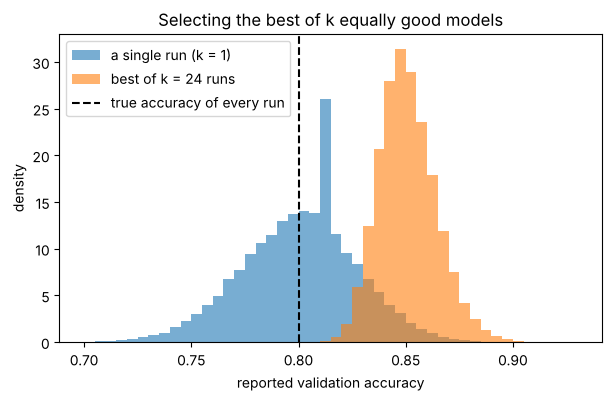

In [18]:
from scipy import integrate

def expected_max_normals(k):           # E[max of k iid N(0,1)] = integral of x * k * phi(x) * Phi(x)^(k-1)
    return integrate.quad(lambda x: x * k * stats.norm.pdf(x) * stats.norm.cdf(x) ** (k - 1), -10, 10)[0]

n_val, acc_true, reps = 200, 0.80, 50_000
se_val = np.sqrt(acc_true * (1 - acc_true) / n_val)
print(f"validation SE at accuracy {acc_true}, n = {n_val}: {se_val:.4f}\n")
print(f"{'k':>4s}{'E[best score]':>16s}{'optimism':>10s}{'SE x E[max]':>14s}")
best_of = {}
for k in (1, 3, 5, 10, 24):
    scores = rng.binomial(n_val, acc_true, size=(reps, k)) / n_val
    best_of[k] = scores.max(1)
    print(f"{k:4d}{best_of[k].mean():16.4f}{best_of[k].mean() - acc_true:+10.4f}{se_val * expected_max_normals(k):14.4f}")

plt.hist(best_of[1], bins=np.arange(0.70, 0.93, 0.005), alpha=0.6, density=True, label="a single run (k = 1)")
plt.hist(best_of[24], bins=np.arange(0.70, 0.93, 0.005), alpha=0.6, density=True, label="best of k = 24 runs")
plt.axvline(acc_true, color="k", ls="--", label="true accuracy of every run")
plt.xlabel("reported validation accuracy"); plt.ylabel("density"); plt.title("Selecting the best of k equally good models")
plt.legend(); plt.show()

Twenty-four equally good configurations, and the winner reports about 85% when every one of them is
an 80% model: 5 points of pure selection. The $\sigma\,\mathbb E[\max]$ approximation tracks the
simulation closely. Choose on a validation set, report on a separate test set, and state the number of
seeds and the spread.

**Try it yourself:** set `n_val = 2000`. The optimism shrinks by about $\sqrt{10}$ — selection bias is
a sampling-noise phenomenon, so more validation data *does* cure it.

## Summary

- A statistic is a random variable; its sampling distribution can be written out for tiny populations and simulated for everything else. Random sampling is what makes inference valid; a biased mechanism stays biased at any $n$.
- Mean and standard deviation have breakdown point 0; median, MAD and trimmed means resist outliers. `ddof=0` versus `ddof=1` differ by the factor $(n-1)/n$.
- $\text{MSE} = \text{bias}^2 + \text{variance}$; the unbiased variance estimator has the largest MSE of the three divisors, and James–Stein beats the unbiased mean vector for every $\theta$ when $p \ge 3$.
- The standard error of a mean is $\sigma/\sqrt n$ and of a proportion $\sqrt{p(1-p)/n}$, exactly; the CLT supplies the normal shape.
- A 95% confidence interval is a procedure with 95% coverage; $z$-with-$s$ under-covers at small $n$, and the Wald interval under-covers near $p = 0$ or $1$ — use $t$ and Wilson.
- The bootstrap resamples the sample to estimate standard errors and percentile intervals for statistics without formulas; it reproduces $s/\sqrt n$ for the mean, handles medians, quantiles and correlations, and fails for the maximum.
- Sample size grows like $1/e^2$: ± 3 points needs about 1,000 observations, ± 1 point about 10,000.
- A test accuracy is a proportion with an SE; compare models on paired disagreements; the best of $k$ noisy scores is biased upward by about $\text{SE} \times \mathbb E[\max_k]$.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.